# 📘 Elastic Net Regression in Machine Learning

## 📖 Introduction
Linear Regression can suffer from overfitting, multicollinearity, unstable coefficients and poor generalization.

Elastic Net combines:
- Ridge (L2)
- Lasso (L1)

Cost:
RSS + λ( αΣ|bj| + (1-α)Σbj² )

## Why Elastic Net?
- Handles multicollinearity
- Performs feature selection
- Reduces overfitting

## Role of Alpha
α=1 Lasso  
α=0 Ridge  
0<α<1 Elastic Net

## Role of Lambda
Small λ weak regularization  
Large λ strong regularization

## Advantages
- Combines Ridge + Lasso
- Flexible
- Stable

## Applications
- Finance
- Genomics
- Medical models


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

np.random.seed(0)
X=np.sort(np.random.rand(40)).reshape(-1,1)
y=np.sin(2*np.pi*X).ravel()+np.random.randn(40)*0.2
X_plot=np.linspace(0,1,200).reshape(-1,1)


## Graph: Alpha Mix Effect

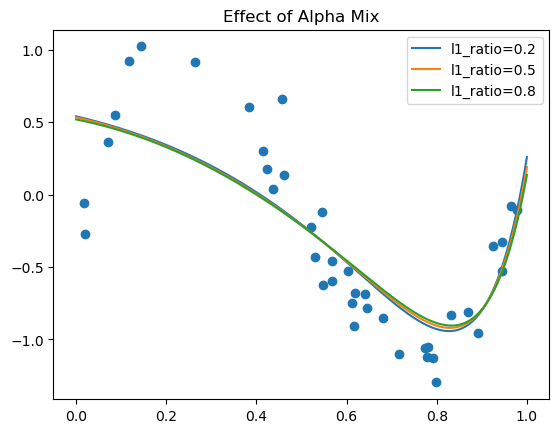

In [6]:
ratios=[0.2,0.5,0.8]

plt.figure()
plt.scatter(X,y)

for r in ratios:
    model=make_pipeline(
        PolynomialFeatures(12),
        ElasticNet(alpha=0.01,l1_ratio=r,max_iter=10000)
    )
    model.fit(X,y)
    plt.plot(X_plot,model.predict(X_plot),label=f'l1_ratio={r}')

plt.legend()
plt.title("Effect of Alpha Mix")
plt.show()


## Graph: Lambda Effect

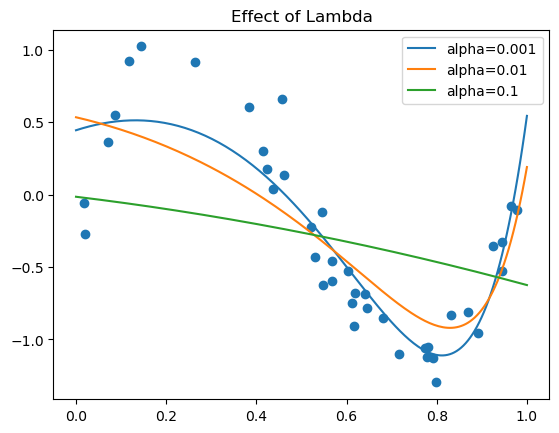

In [7]:
alphas=[0.001,0.01,0.1]

plt.figure()
plt.scatter(X,y)

for a in alphas:
    model=make_pipeline(
        PolynomialFeatures(12),
        ElasticNet(alpha=a,l1_ratio=0.5,max_iter=10000)
    )
    model.fit(X,y)
    plt.plot(X_plot,model.predict(X_plot),label=f'alpha={a}')

plt.legend()
plt.title("Effect of Lambda")
plt.show()


## Python Implementation

In [8]:
X2=np.random.randn(100,5)
y2=3*X2[:,0]+2*X2[:,1]+np.random.randn(100)

model=ElasticNet(alpha=1.0,l1_ratio=0.5)
model.fit(X2,y2)

print(model.coef_)


[1.67634691 0.89070284 0.         0.         0.        ]
